# Lesson 10. Where does a point go when the camera turns?

[Course plan](../../README.md)

A wire triangle stands on a table. The camera slides right, and the triangle ends up on its left. The wire has the same length and occupies the same patch of table. What moved was the place from which we measure “to the right.” Before drawing pixels, we need a way to keep track of that reference.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. The triangle in two windows

Both drawings are overhead views. Horizontal position is $x$ and depth is $z$. The third coordinate, $y$, still enters the calculation. In the right-hand view the grid always starts at the camera. The orange vertex can move on its own. Two other corners are fixed to a common frame. “Point x” moves just the vertex and changes the shape. “Object x” shifts the entire frame without bending it. “Camera x” moves the measuring origin. “Camera yaw” turns its axes. A short green line shows the camera's forward direction.

The right-hand coordinates start at $(1,1,4)$. Suppose “Object x” and “Camera x” both increase from 1 to 2. On the left, the frame and camera travel one meter together. On the right, all three vertices stay put. The world positions have changed, yet a picture taken by this camera would look the same.

In [2]:
display(demos.geometry_lab(10, "en"))

## 2. Three rulers attached to a tripod

A camera on a little tripod gives us a place to start a measurement. Now attach three rulers to it at right angles. One reads “right”, one reads “down”, the third reads “forward”. Marking the starting point alone would leave something out. Two tripods could have their feet in exactly the same place and face different ways. They would then give different readings for the very same vertex. An origin, a set of directions and a unit of length make up a **coordinate frame**.

The green arrow on the left lies in the plane of the table and points into the scene. The downward axis goes out of the drawing. The overhead view therefore cannot distinguish camera points $(1,1,4)$ and $(1,3,4)$. Both put their mark at the same place on the paper, despite being two metres apart vertically. The calculation keeps all three numbers when changing frames. Only the diagram drops one of them so that we can follow what happens on the table.

A reading of “one metre to the right of the camera” carries a sign. If the vertex crosses to the left, the ruler keeps its orientation: its readings pass through zero and become negative. A negative depth places a vertex behind the camera. The length of wire connecting two vertices cannot turn negative on that account. A sign belongs to a particular direction. The physical separation of two points takes motion along all the directions into account and is always nonnegative. The stationary tabletop gives us room to untangle the two measurements before we need them in an image.

## 3. Three numbers, three origins

Lengths in this scene are in meters. The camera axes point right ($x$), down ($y$) and forward ($z$). This choice makes increasing $y$ move a pixel down the image later. The triple $(1,1,4)$ measures one meter right, one down and four forward from a particular origin. A negative $x$ means the same distance to the left.

The selected vertex starts at $p=(1,1,4)$ in the frame attached to the triangle. The frame's own origin lies at world point $O=(1,0,0)$. The axes are parallel for now. Adding matching components gives the world position:

$$
P=O+p=(1+1,\;0+1,\;0+4)=(2,1,4).
$$

A third origin is the camera center $C=(1,0,0)$ in the world. The **displacement** $d$ runs from that center to the vertex. It has a length and a direction. Subtracting the starting point from the endpoint gives it:

$$
d=P-C=(2-1,\;1-0,\;4-0)=(1,1,4).
$$

If the camera reaches $C=(2,0,0)$, the first component becomes $2-2=0$. The vertex is straight ahead horizontally, although its world $x$ is still 2. Translating every point together preserves the displacement between any pair because the common addition cancels in the subtraction.

In [3]:
p = np.array([1., 1., 4.])
O = np.array([1., 0., 0.])
C = np.array([1., 0., 0.])
P = O + p
print("P =", P, "   P-C =", P - C)
assert np.array_equal((P + [1, 0, 0]) - (C + [1, 0, 0]), P - C)

P = [2. 1. 4.]    P-C = [1. 1. 4.]


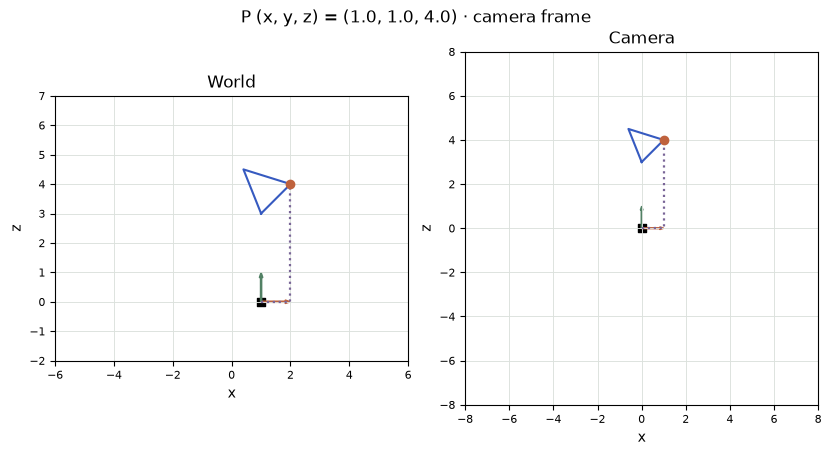

In [4]:
fig = demos.frame_figure("en")
plt.show()

## 4. One wire, several moves

One edge runs from $U=(1,0,3)$ to the orange vertex $P=(2,1,4)$ in world space. Starting at $U$, the other end lies one metre to the right, one down and one forward. The arrow $P-U=(1,1,1)$ describes the **edge**. A vertex has an address; an edge has the difference between two addresses. Sliding the frame a metre right moves its endpoints to $(2,0,3)$ and $(3,1,4)$. Their difference is still $(1,1,1)$.

We can check the wire's length without rotating the camera. Its projection onto the table travels one metre to the right and one forward. By Pythagoras its squared length in that plane is $1^2+1^2=2$ m². There is also a vertical separation of one metre. The squared length in space becomes $2+1^2=3$ m², giving a wire of length $\sqrt{3}\approx1.732$ m. Both endpoints can move in a camera image. If the **spatial** distance between their camera coordinates changes, a scale factor has crept in somewhere, or the units have been mixed.

| Change from the starting pose | World $P$, m | World $P-C$, m | What happens to the edge |
|---|---|---|---|
| Camera and frame both at $x=1$ | $(2,1,4)$ | $(1,1,4)$ | length $\sqrt{3}$ m |
| Frame alone at $x=2$ | $(3,1,4)$ | $(2,1,4)$ | both ends moved right |
| Camera alone at $x=2$ | $(2,1,4)$ | $(0,1,4)$ | both ends stayed on the table |
| Both at $x=2$ | $(3,1,4)$ | $(1,1,4)$ | same view from the camera |

The camera axes stay parallel to the world axes throughout the table. Each row starts from the same initial pose. The last and first rows make an interesting pair. The relative measurement $P-C$ alone cannot reveal which bodies have moved. The world coordinates in the next column can tell those setups apart immediately. Later, when both cameras and a scene come from photographs, a common translation will be one way to change their description while preserving every view.

In [5]:
U = O + np.array([0., 0., 3.])
for shift_object, shift_camera in [(0,0), (1,0), (0,1), (1,1)]:
    shift = np.array([shift_object, 0., 0.])
    center = C + [shift_camera, 0., 0.]
    tip, base = P + shift, U + shift
    print(f"Oₓ={O[0]+shift_object:.0f}, Cₓ={center[0]:.0f}:",
          tip-center, f"  |P−U|={np.linalg.norm(tip-base):.3f} m")

Oₓ=1, Cₓ=1: [1. 1. 4.]   |P−U|=1.732 m
Oₓ=2, Cₓ=1: [2. 1. 4.]   |P−U|=1.732 m
Oₓ=1, Cₓ=2: [0. 1. 4.]   |P−U|=1.732 m
Oₓ=2, Cₓ=2: [1. 1. 4.]   |P−U|=1.732 m


## 5. Reading a direction along a different axis

The world axes stay put. The camera turns $30^\circ$ to the right about its vertical axis. Its unit directions, written in world coordinates, now read

$$
r=(0.866,0,-0.5),\quad b=(0,1,0),\quad f=(0.5,0,0.866).
$$

The letters stand for right, down and forward. A unit direction has length 1. For $f$, the sum of squares is about $0.5^2+0.866^2=1$. The value 0.866 is rounded here and below. Turning the original direction keeps its length. The numbers 0.5 and 0.866 are the sine and cosine of the angle, the sideways and forward fractions of a unit arrow turned away from straight ahead.

How much of $d=(1,1,4)$ lies along the new right axis? The first meter in world $x$ contributes $0.866$ m. The meter in world $y$ contributes zero. Four meters in world $z$ contribute $4\cdot(-0.5)=-2$ m. Together that gives $0.866+0-2=-1.134$ m. This sum of matching products is a **dot product**. With a unit axis it measures signed length along that axis.

The down component is $0\cdot1+1\cdot1+0\cdot4=1$. The forward component is $0.5\cdot1+0\cdot1+0.866\cdot4=3.964$. After the turn the vertex lies left, down and still in front. Its overhead position is just the intersection of $x=-1.134$ and $z=3.964$. The wire and its distance from the camera haven't changed. What changed was the orientation of the three rulers.

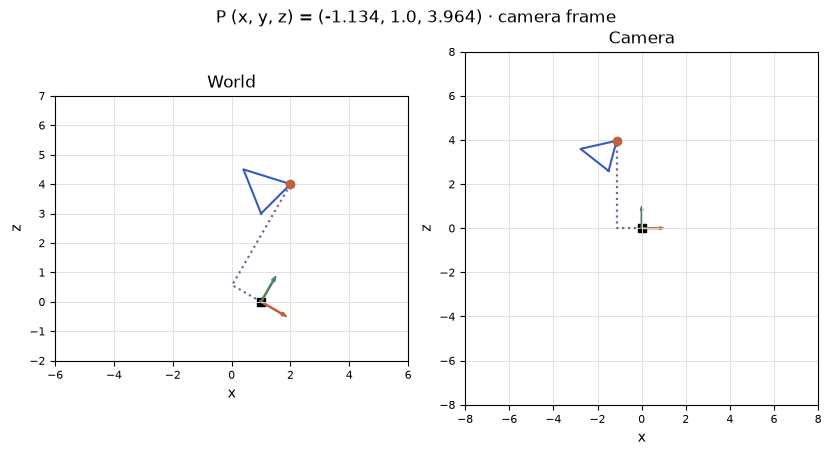

In [6]:
fig = demos.frame_figure("en", yaw=30)
plt.show()

## 6. Taking an arrow apart and putting it back together

The purple path goes from the camera to the vertex in two legs on the table. The first runs parallel to the camera's right axis, the second parallel to its forward axis. At $30^\circ$ the first leg runs **against** the orange arrow. At zero yaw it used to go to the right. The green axis has swept past the horizontal direction to the vertex, changing the sign of the sideways reading. The actual world arrow from camera to wire has not turned at all.

The reading of $-1.134$ m can be checked in reverse. The leg along the right axis contributes approximately $-1.134(0.866,0,-0.5)=(-0.982,0,0.567)$ m in world coordinates. The forward leg contributes $3.964(0.5,0,0.866)=(1.982,0,3.433)$ m. Including the downward motion $(0,1,0)$ gives $-0.982+1.982=1$ in the first slot, 1 in the second and $0.567+3.433=4$ in the third. That reconstructs the original arrow $d$. Multiplication by an axis distributes the metres across the world directions. The sign tells us which way along the axis to travel.

What happens beyond a small turn? In the graph below the camera stays at $(1,0,0)$ and makes a complete turn around the vertical. The vertex changes two readings, sideways and forward. The sideways reading passes through zero as the camera turns to face the vertex horizontally. At that instant the **depth** reaches its maximum, the overhead arrow length $\sqrt{1^2+4^2}=\sqrt{17}$ m. This still leaves out the vertical component of the full distance. Where depth is negative the point continues to exist in the world and has perfectly good camera coordinates. Whether it belongs in a photograph is a separate test.

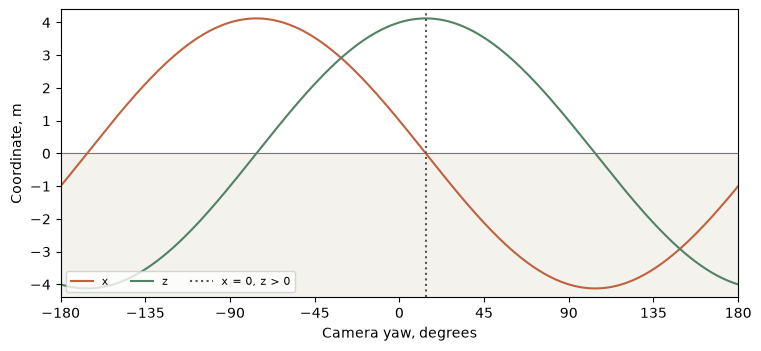

In [7]:
degrees = np.linspace(-180, 180, 361)
trace = []
for yaw in degrees:
    basis = geo.quaternion_matrix(geo.axis_angle_quaternion([0, 1, 0], yaw))
    trace.append(geo.world_to_camera(P, C, basis))
trace = np.array(trace)
np.testing.assert_allclose(trace[:,0]**2 + trace[:,2]**2, 17.)
fig, ax = plt.subplots(figsize=(7.5, 3.4), layout="constrained")
ax.axhspan(-4.4, 0, color="#f3f2ec")
ax.axhline(0, color="#777", lw=.8)
ax.plot(degrees, trace[:,0], color=demos.ORANGE, label="x")
ax.plot(degrees, trace[:,2], color=demos.GREEN, label="z")
ax.axvline(np.rad2deg(np.arctan2(1,4)), color="#555", ls=":", label="x = 0, z > 0")
ax.set(xlim=(-180,180), ylim=(-4.4,4.4), xticks=np.arange(-180,181,45),
       xlabel="Camera yaw, degrees",
       ylabel="Coordinate, m")
ax.legend(ncol=3, loc="lower left", fontsize=8)
plt.show()

## 7. Three rulers in one matrix

Writing the axes as columns gives $B=[r\ b\ f]$. A column contains three numbers from top to bottom. To compute all three dot products at once we need those axes as **rows**. The superscript $\mathsf T$ means transpose, swapping rows with columns.

$$
p_c=B^{\mathsf T}(P-C)
=\begin{bmatrix}0.866&0&-0.5\\0&1&0\\0.5&0&0.866\end{bmatrix}
\begin{bmatrix}1\\1\\4\end{bmatrix}
\approx\begin{bmatrix}-1.134\\1\\3.964\end{bmatrix}.
$$

Multiplying a matrix by a column amounts to the three familiar calculations in order. To go back we add three world arrows: $P=C+r\,p_{c,x}+b\,p_{c,y}+f\,p_{c,z}=C+Bp_c$. Transposing undoes the rotation because the axes are perpendicular and have unit length. An axis dotted with itself gives 1 and dotted with its neighbor gives 0. Consequently $B^{\mathsf T}B$ has ones on its diagonal and zeros everywhere else.

Turning the object's own frame adds a step. Matrix $A$ takes object axes into the world. A $90^\circ$ turn of the frame about $z$ carries local point $(1,1,4)$ to $(-1,1,4)$. Translation by $O=(1,0,0)$ gives world point $(0,1,4)$. Adding $O$ before turning would give $(-1,2,4)$, since the turn then carries the frame origin along too. The whole chain $p_c=B^{\mathsf T}(O+Ap-C)$ reads from the inside out.

In [8]:
angle = np.deg2rad(30)
c, s = np.cos(angle), np.sin(angle)
B = np.array([[c,0,s], [0,1,0], [-s,0,c]])
pc = geo.world_to_camera(P, C, B)
print("B.T =\n", B.T, "\np_camera =", pc)
np.testing.assert_allclose(C + B @ pc, P)
np.testing.assert_allclose(B.T @ B, np.eye(3), atol=1e-14)

B.T =
 [[ 0.866  0.    -0.5  ]
 [ 0.     1.     0.   ]
 [ 0.5    0.     0.866]] 
p_camera = [-1.134   1.      3.9641]


In [9]:
A = np.array([[0,-1,0], [1,0,0], [0,0,1]])
print("O+A@p =", O + A @ p, "    A@(O+p) =", A @ (O+p))
print("world distance =", np.linalg.norm(P-C), "  camera distance =", np.linalg.norm(pc))

O+A@p = [0. 1. 4.]     A@(O+p) = [-1.  2.  4.]
world distance = 4.242640687119285   camera distance = 4.242640687119285


## 8. Three rows and an extra column in a pose file

We now have two ways to recover a position on the table. When the camera axes $B$ and its world position $C$ are stored, we can go directly to $C+Bp_c$. A file can instead store the transformation **from world to camera**. Expanding it reveals what its entries mean. With $W=B^{\mathsf T}$, distributing the multiplication over subtraction gives $W(P-C)=WP-WC$. The second term is identical for all vertices in the exposure. It is often stored as the translation $t=-WC$, leaving a multiplication and an addition in the point loop, $p_c=WP+t$.

Here is where a sign or a frame can go missing. Our camera is at $C=(1,0,0)$ m with the same $30^\circ$ turn. The column $WC$ equals $(0.866,0,0.5)$ because the first column of $W$ is multiplied by one and its other two columns by zero. The translation column is $t=(-0.866,0,-0.5)$ m. Three distinct triples are involved. $C$ gives the world position of the camera. $-C$ points from the camera to the world origin in world axes. $t$ measures that last arrow in **camera axes**. It has a depth component even though the tripod did not travel along the world depth axis.

Substituting the camera center itself makes a handy check on a pose file. At $P=C$, the result must be $WP+t=WC-WC=(0,0,0)$, since the camera is at zero displacement from itself. Substituting the world origin $P=(0,0,0)$ instead gives precisely $t$. The two tested points have a physical meaning, even without an image. Sometimes $t$ really does coincide with $-C$, for example with parallel axes. Testing only that pose lets a mistake pass. A known nonzero turn exposes the difference.

To recover the tripod position from a file containing only $W$ and $t$, we can start at the camera origin and follow the same steps backwards. From $0=WC+t$ we have $WC=-t$. The inverse of $W$ turns camera axes back into world axes, so $C=-W^{\mathsf T}t$. Swapping rows and columns works because the three axes are perpendicular unit arrows. A ruler stretched to twice its length would multiply by two in the forward calculation. Its inverse would divide by two, while its transpose would still multiply by two. This shortcut belongs to a rotation.

For a batch of vertices the rotation and translation can also share a single table. Each input point acquires a fourth entry equal to one. The first three rows of the expanded table contain one row of $W$ and one entry from $t$. Under the row-times-column rule the fourth product multiplies the translation by one. The final row contains three zeros and a one, so a point keeps its last coordinate. A direction in space gets a zero in that slot: translation is multiplied by zero and leaves the arrow alone.

$$
\begin{bmatrix}p_c\\1\end{bmatrix}=
\begin{bmatrix}W&t\\0\;0\;0&1\end{bmatrix}
\begin{bmatrix}P\\1\end{bmatrix}.
$$

Each vertical vector contains four numbers, and the upper left block contains nine. The table bundles operations we have already worked through. The same matrix takes care of a wire's endpoints and of their difference when the respective inputs carry a one or a zero. Moving the camera changes both addresses. Subtracting the transformed endpoints cancels the translation column.

In [10]:
W = B.T
t = -W @ C
T = np.eye(4)
T[:3, :3], T[:3, 3] = W, t
for name, value in [("P", np.r_[P, 1.]), ("C", np.r_[C, 1.]),
                    ("P−U", np.r_[P-U, 0.])]:
    print(name, "→", np.round(T @ value, 4))
np.testing.assert_allclose((T @ np.r_[P-U,0.])[:3], W @ (P-U))
np.testing.assert_allclose(-B @ t, C, atol=1e-14)

P → [-1.134   1.      3.9641  1.    ]
C → [0. 0. 0. 1.]
P−U → [0.366 1.    1.366 0.   ]


## 9. What stays in the drawing?

**An experiment.** The camera initially looks straight ahead. What happens to the relative position if the camera moves one meter right and the vertex moves two?

<details>
<summary>Working it out</summary>

The new world $x$ of the vertex is $2+2=4$. The camera reaches $1+1=2$. The right-hand view now reads $4-2=2$ instead of 1. The other coordinates remain 1 and 4. The rightward component grew by the difference in the displacements, $2-1=1$ m.

</details>

**Another angle.** Which turn puts the initial direction $(1,1,4)$ exactly in the horizontal middle?

<details>
<summary>Working it out</summary>

The new right component must satisfy $1\cos\theta-4\sin\theta=0$. Dividing by $4\cos\theta$ gives $\tan\theta=1/4$. Tangent is the ratio of the sideways leg of the triangle to the forward leg. Its inverse takes us back to an angle, about $14.04^\circ$. At the nearest whole degree, $14^\circ$, around $0.003$ m remains. The vertical coordinate is still 1, so the centering is horizontal only.

</details>

## 10. Three camera readings without a sensor

**Facing away.** A point has camera coordinates $(0,0,-4)$ m. Which world point does that describe for the original camera with zero rotation? Which world point would give the same readings after a $180^\circ$ turn on the spot?

<details>
<summary>Worked answer</summary>

At zero yaw, four metres backward from the camera leads to $(1,0,-4)$. After the turn its forward arrow points along negative world $z$. Four metres against that arrow now leads to $(1,0,4)$. The camera addresses agree in these two experiments. The world addresses differ, and the distance to the respective point is four metres in each case.
</details>

**A suspicious pose.** A file supplies $W$ and $t=(0,0,0)$ for a camera known to be at $(1,0,0)$ with a right turn of $30^\circ$. Where does that file put the camera itself?

<details>
<summary>Worked answer</summary>

The result is $WC=(0.866,0,0.5)$ instead of zero. The missing translation must cancel every entry, giving $(-0.866,0,-0.5)$ m. The sign can be checked at the world origin: that point really does lie somewhat behind and to the left of the turned camera.
</details>

**A scanner in millimetres.** A scanner returns $(2000,1000,4000)$ in millimetres while the camera position is in metres. What goes wrong with a horizontal displacement computed as $2000-1$?

<details>
<summary>Worked answer</summary>

The numbers carry different units. In metres the scanner point is $(2,1,4)$ and $2-1=1$ m. With the camera expressed in millimetres the subtraction is $2000-1000=1000$ mm, the same length. A rotation is dimensionless and preserves the length unit of its input, so a conversion error would survive it.
</details>

The next lesson carries the same triple onto a sensor. The sideways displacement and depth now refer to a single frame. They can serve as the sides of a triangle to locate a point relative to the center of an image.